# From attention to action
### An evidence-led analysis of the e-commerce customer journey

**DevLab · Week 6 · January–February 2020**

Visits describe attention, carts suggest intent, and purchases show completed action. The important question is not just how many events occurred, but how many *people* progressed through an observable journey, where the largest losses happened, and which opportunities deserve a growth experiment.

> **Decision question:** Where does the largest measurable loss occur between product discovery and purchase, and what should the product team investigate first?

This notebook runs end-to-end from the two-month data archive included in `data/`, saves **seven publication-ready charts** to `visuals/`, and preserves all tables and charts in the executed notebook itself. Charts are not numbered; each tells a specific part of the story.

## Measurement contract

The primary funnel counts **unique user-month journeys**: a user must view a product, later add a product to cart, then later purchase (products need not match). January and February are treated as separate journeys. A second, unordered count tracks who performed each action, regardless of sequence; those counts are **not** conversion probabilities. Category and brand rates separately measure user overlap within the same label, *not* chronological or exact-product conversions.

The archive is read **directly, in chunks**, without extracting 1 GB of CSV files. Product and category completeness, nonpositive prices, and event types are inspected before computing rates. "View → purchase" in the primary funnel intentionally includes the intermediate cart stage.

In [1]:
from pathlib import Path
from collections import Counter
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
ARCHIVE = ROOT / "data" / "source_data.zip"
if not ARCHIVE.is_file():
    candidates = [ROOT / "DOC-20261018-WA0036.zip", ROOT.parent / "DOC-20261018-WA0036.zip"]
    ARCHIVE = next((p for p in candidates if p.is_file()), ARCHIVE)
if not ARCHIVE.is_file():
    raise FileNotFoundError("The two-month archive should be at task 1/data/source_data.zip")

FILES = {"Jan": "2020-Jan.csv", "Feb": "2020-Feb.csv"}
with zipfile.ZipFile(ARCHIVE) as z:
    assert all(n in z.namelist() for n in FILES.values()), "Archive lacks January or February CSV"

CHUNK_SIZE = 300_000
DTYPES = {"user_id": "Int64", "product_id": "Int64", "event_type": "category", "category_code": "string", "brand": "string", "price": "float64"}
COLUMNS = ["event_time", "event_type", "product_id", "category_code", "brand", "price", "user_id"]
STAGES = ("view", "cart", "purchase")
VIZ = ROOT / "visuals"
VIZ.mkdir(exist_ok=True)
NAVY, TEAL, ORANGE, PALE, GREY = "#18324b", "#168c8b", "#d87948", "#e8f1f2", "#7e8e9d"
sns.set_theme(style="whitegrid", font_scale=1.03)
plt.rcParams.update({"figure.dpi": 125, "savefig.dpi": 180, "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.16, "font.family": "DejaVu Sans"})

def chunks(month, fields=COLUMNS):
    with zipfile.ZipFile(ARCHIVE) as z, z.open(FILES[month]) as handle:
        needed = {k: v for k, v in DTYPES.items() if k in fields}
        for chunk in pd.read_csv(handle, usecols=fields, dtype=needed, chunksize=CHUNK_SIZE):
            if "event_time" in fields:
                chunk["event_time"] = pd.to_datetime(chunk.event_time, format="%Y-%m-%d %H:%M:%S UTC", utc=True, errors="coerce")
            yield chunk

def pct(num, den):
    return 100 * num / den if den else np.nan

def save_chart(fig, name):
    fig.savefig(VIZ / name, bbox_inches="tight", facecolor="white", dpi=200)
    plt.show()
    plt.close(fig)

print("Dataset:", ARCHIVE.name, "| months:", ", ".join(FILES))
print("Graphics folder:", VIZ.resolve())

Dataset: source_data.zip | months: Jan, Feb
Graphics folder: /mnt/data/task 1/visuals


## What the records can support

Start with reliable counts. A missing `category_code` is not a new category; a missing brand is not zero demand. Purchase-event `price` is an **item-event amount**, not order-level average basket value. The analysis keeps each concept in its proper unit.

In [2]:
audit, event_counts = Counter(), Counter()
category_view_counts, brand_purchase_counts = Counter(), Counter()
product_counts = Counter()
by_month, category_fragments, brand_fragments, purchase_price_fragments = {}, [], [], []

for month in FILES:
    stage_frames = []
    for df in chunks(month):
        audit[month, "rows"] += len(df)
        audit[month, "missing_category"] += int(df.category_code.isna().sum())
        audit[month, "missing_brand"] += int(df.brand.isna().sum())
        audit[month, "missing_user"] += int(df.user_id.isna().sum())
        audit[month, "invalid_time"] += int(df.event_time.isna().sum())
        audit[month, "nonpositive_price"] += int(df.price.le(0).sum())
        event_counts.update({(month, str(k)): int(v) for k, v in df.event_type.value_counts().items()})
        category_view_counts.update(df.loc[df.event_type.eq("view") & df.category_code.notna(), "category_code"].value_counts().to_dict())
        brand_purchase_counts.update(df.loc[df.event_type.eq("purchase") & df.brand.notna(), "brand"].value_counts().to_dict())
        group = df.loc[df.product_id.notna() & df.event_type.isin(STAGES)].groupby(["product_id", "event_type"], observed=True).size()
        product_counts.update({(int(pid), str(event)): int(num) for (pid, event), num in group.items()})
        good = df.user_id.notna() & df.event_time.notna() & df.event_type.isin(STAGES)
        stage_frames.append(df.loc[good, ["user_id", "event_type", "event_time"]].copy())
        cat_good = df.user_id.notna() & df.category_code.notna() & df.event_type.isin(STAGES)
        category_fragments.append(df.loc[cat_good, ["user_id", "category_code", "event_type"]].copy())
        brand_good = df.user_id.notna() & df.brand.notna() & df.event_type.isin(STAGES)
        brand_fragments.append(df.loc[brand_good, ["user_id", "brand", "event_type"]].copy())
        purchase_price_fragments.append(df.loc[df.event_type.eq("purchase") & df.price.notna(), "price"].to_numpy())
    by_month[month] = pd.concat(stage_frames, ignore_index=True)
    print(f"{month}: {audit[month, 'rows']:,} events loaded")

coverage = pd.DataFrame([{"month": m, "events": audit[m, "rows"], "category tagged %": pct(audit[m, "rows"] - audit[m, "missing_category"], audit[m, "rows"]),
                          "brand tagged %": pct(audit[m, "rows"] - audit[m, "missing_brand"], audit[m, "rows"]), "missing user IDs": audit[m, "missing_user"],
                          "invalid timestamps": audit[m, "invalid_time"], "nonpositive prices": audit[m, "nonpositive_price"]} for m in FILES]).set_index("month")
event_mix = pd.DataFrame([{"month": m, "event": e, "count": event_counts[m, e]} for m in FILES for e in ("view", "cart", "purchase", "remove_from_cart")]).pivot(index="event", columns="month", values="count").fillna(0).astype(int)
print("Data quality and coverage")
display(coverage.round(2))
print("Raw event distribution (not distinct users)")
display(event_mix)

Jan: 4,264,752 events loaded


Feb: 4,156,682 events loaded
Data quality and coverage


,events,category tagged %,brand tagged %,missing user IDs,invalid timestamps,nonpositive prices
month,,,,,,
Jan,4264752,1.75,58.36,0,0,7662
Feb,4156682,1.86,56.07,0,0,71291


Raw event distribution (not distinct users)


month,Feb,Jan
event,,
cart,1148694,1148323
purchase,241993,263797
remove_from_cart,812409,815024
view,1953586,2037608


## The path through the funnel

Events are matched within each month using timestamps rather than raw row order: find a user's earliest view, the earliest cart at or after that view, and the earliest purchase at or after that eligible cart. Ties are accepted because timestamps resolve to one second. This user-level funnel can connect actions on different products; it should not be called a product-specific conversion path.

In [3]:
journeys = {}
participation, ordered = {}, {}
latency_parts = []
for month, events in by_month.items():
    views = events.loc[events.event_type.eq("view"), ["user_id", "event_time"]]
    carts = events.loc[events.event_type.eq("cart"), ["user_id", "event_time"]]
    purchases = events.loc[events.event_type.eq("purchase"), ["user_id", "event_time"]]
    first_view = views.groupby("user_id", sort=False).event_time.min()
    participation[month] = {"view": len(first_view), "cart": carts.user_id.nunique(), "purchase": purchases.user_id.nunique()}
    cart_candidates = carts.join(first_view.rename("first_view"), on="user_id")
    qualified_cart = cart_candidates.loc[cart_candidates.event_time.ge(cart_candidates.first_view)].groupby("user_id", sort=False).event_time.min()
    purchase_candidates = purchases.join(qualified_cart.rename("first_cart"), on="user_id")
    qualified_purchase = purchase_candidates.loc[purchase_candidates.event_time.ge(purchase_candidates.first_cart)].groupby("user_id", sort=False).event_time.min()
    ordered[month] = {"view": len(first_view), "cart": len(qualified_cart), "purchase": len(qualified_purchase)}
    lag = (qualified_purchase - first_view.reindex(qualified_purchase.index)).dt.total_seconds().div(3600)
    latency_parts.append(lag.dropna())
    journeys[month] = {"first_view": first_view, "first_cart": qualified_cart, "first_purchase": qualified_purchase}

monthly_users = pd.DataFrame.from_dict(ordered, orient="index")
funnel = monthly_users.sum()
rates = {"view → cart": pct(funnel.cart, funnel["view"]), "cart → purchase": pct(funnel.purchase, funnel.cart), "view → purchase": pct(funnel.purchase, funnel["view"])}
latency = pd.concat(latency_parts, ignore_index=True)
print("Ordered user-month funnel")
display(monthly_users)
print("Unordered event participation — distinct users *per month*")
display(pd.DataFrame.from_dict(participation, orient="index"))
print("Ordered transition rates (%)")
display(pd.Series(rates, name="rate %").round(2).to_frame())
assert (monthly_users["view"] >= monthly_users["cart"]).all() and (monthly_users["cart"] >= monthly_users["purchase"]).all()

Ordered user-month funnel


,view,cart,purchase
Jan,397775,75219,25426
Feb,379246,72465,23102


Unordered event participation — distinct users *per month*


,view,cart,purchase
Jan,397775,92653,28220
Feb,379246,89269,25759


Ordered transition rates (%)


,rate %
view → cart,19.01
cart → purchase,32.86
view → purchase,6.25


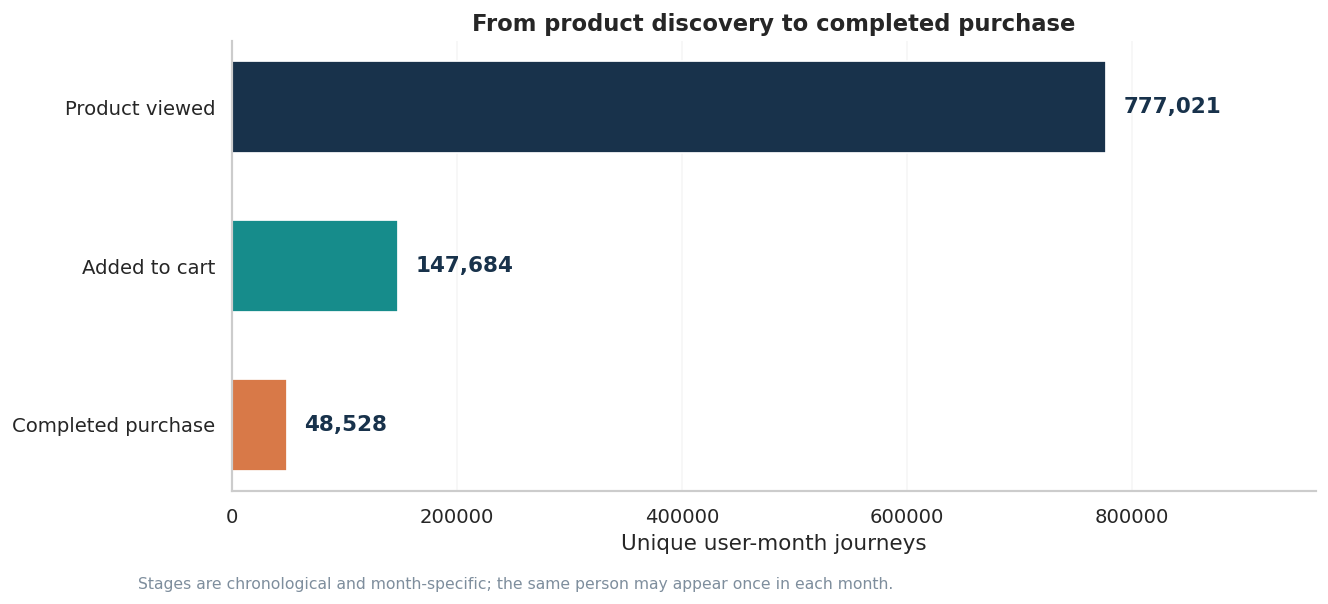

In [4]:
fig, ax = plt.subplots(figsize=(10.8, 4.7))
labels = ["Product viewed", "Added to cart", "Completed purchase"]
values = funnel.loc[list(STAGES)].to_numpy()
bars = ax.barh(labels[::-1], values[::-1], color=[ORANGE, TEAL, NAVY], height=.58)
ax.set_xlim(0, values[0] * 1.24)
for bar, n in zip(bars, values[::-1]):
    ax.text(bar.get_width() + values[0] * .02, bar.get_y() + bar.get_height()/2, f"{n:,.0f}", va="center", fontweight="bold", color=NAVY)
ax.set(title="From product discovery to completed purchase", xlabel="Unique user-month journeys", ylabel="")
ax.grid(axis="y", visible=False)
fig.text(.11, -.02, "Stages are chronological and month-specific; the same person may appear once in each month.", color=GREY, fontsize=9)
fig.tight_layout()
save_chart(fig, "funnel_user_journey.png")

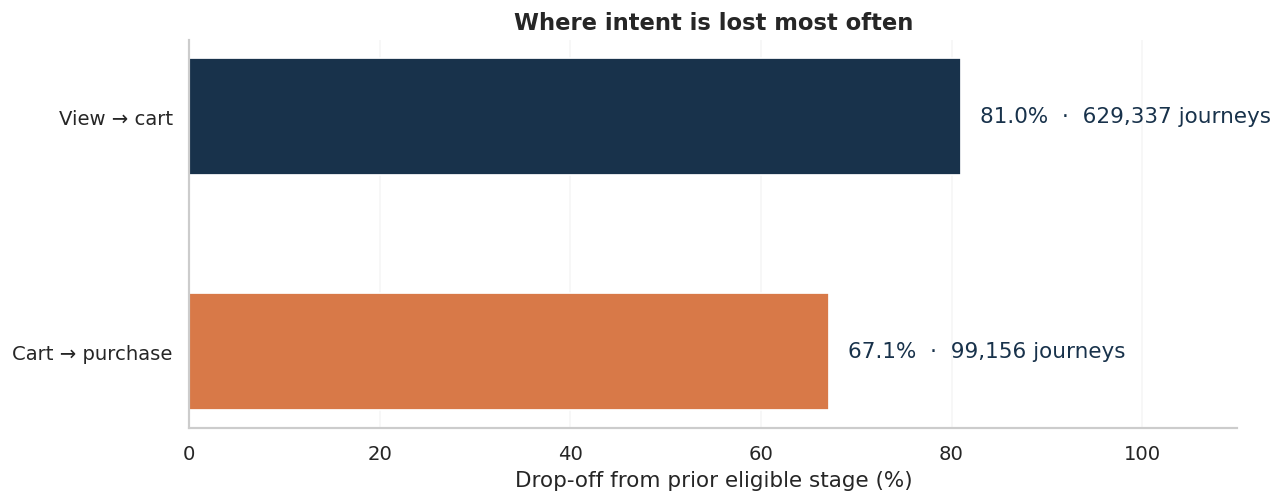

,step,users lost,drop-off %
0,View → cart,629337,80.99
1,Cart → purchase,99156,67.14


In [5]:
loss = pd.DataFrame({"step": ["View → cart", "Cart → purchase"],
                     "users lost": [funnel["view"]-funnel.cart, funnel.cart-funnel.purchase],
                     "drop-off %": [100-rates["view → cart"], 100-rates["cart → purchase"]]})
fig, ax = plt.subplots(figsize=(10.5, 4.2))
bars = ax.barh(loss.step[::-1], loss["drop-off %"][::-1], height=.5, color=[ORANGE, NAVY])
ax.set_xlim(0, 110)
for bar, row in zip(bars, loss.iloc[::-1].itertuples(index=False)):
    ax.text(bar.get_width()+2, bar.get_y()+bar.get_height()/2, f"{row[2]:.1f}%  ·  {row[1]:,} journeys", va="center", color=NAVY)
ax.set(xlabel="Drop-off from prior eligible stage (%)", ylabel="", title="Where intent is lost most often")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_chart(fig, "transition_dropoff.png")
display(loss.round(2))

## Category discovery and purchase overlap

The **eight categories with the highest view-event volume** define the comparison. For each category, we measure the share of its viewing users who also carted or purchased an item tagged with that category. This is an *unordered, labelled-subset* measure, not the ordered overall funnel. Category coverage is shown above because selection bias can be severe when tagging is incomplete.

,category,view events,view users,cart users,purchase users,view → cart %,cart → purchase %,view → purchase %
0,appliances.environment.vacuum,48522,15431,3883,1366,18.69,32.29,6.86
1,furniture.living_room.cabinet,10670,5377,760,119,10.01,14.34,1.82
2,apparel.glove,10584,4965,4128,1932,38.13,43.41,18.43
3,stationery.cartrige,8503,4313,2265,1025,21.89,42.38,9.90
4,accessories.bag,7220,3147,146,45,3.88,30.14,1.21
5,furniture.bathroom.bath,6923,3602,1164,384,17.93,30.67,6.55
6,appliances.personal.massager,2822,1335,151,35,9.06,23.18,2.32
7,appliances.personal.hair_cutter,2252,1141,113,28,6.92,23.01,2.02


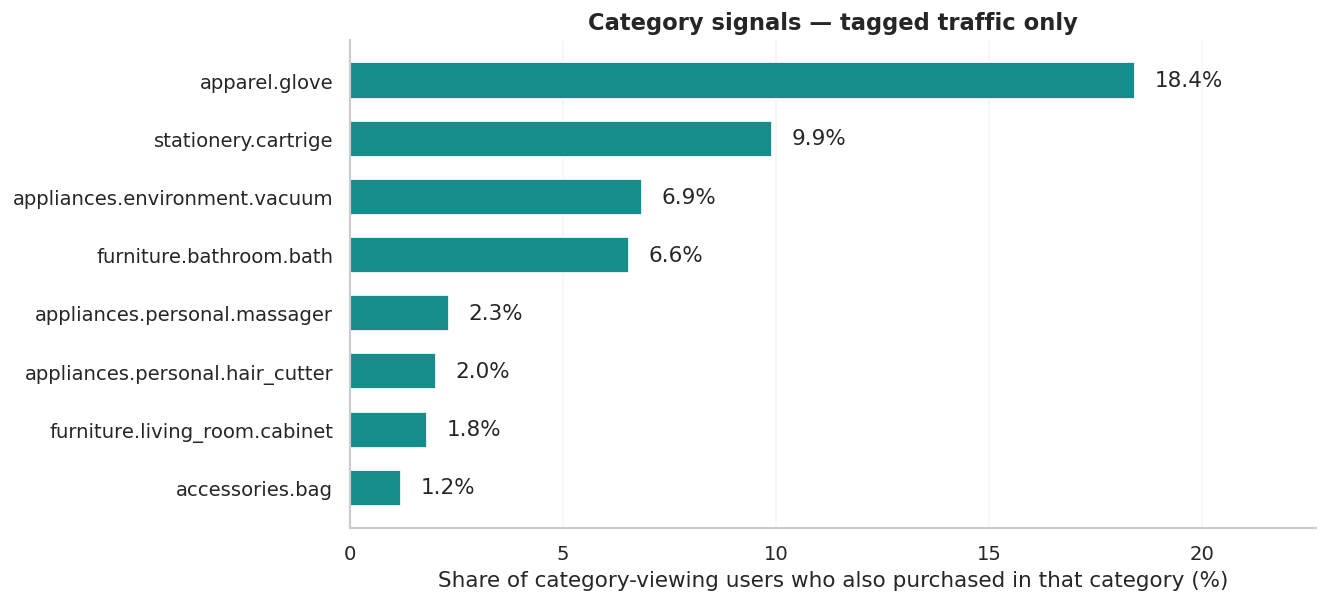

In [6]:
category_rows = pd.concat(category_fragments, ignore_index=True)
top_categories = [str(k) for k, _ in category_view_counts.most_common(8)]
category_rows = category_rows.loc[category_rows.category_code.isin(top_categories)]
category_rows = category_rows.drop_duplicates(["user_id", "category_code", "event_type"])
category_stats = []
for cat in top_categories:
    sub = category_rows.loc[category_rows.category_code.eq(cat)]
    seen = {e: set(sub.loc[sub.event_type.eq(e), "user_id"].astype("int64")) for e in STAGES}
    category_stats.append({"category": cat, "view events": category_view_counts[cat], "view users": len(seen["view"]),
                           "cart users": len(seen["cart"]), "purchase users": len(seen["purchase"]),
                           "view → cart %": pct(len(seen["view"] & seen["cart"]), len(seen["view"])),
                           "cart → purchase %": pct(len(seen["cart"] & seen["purchase"]), len(seen["cart"])),
                           "view → purchase %": pct(len(seen["view"] & seen["purchase"]), len(seen["view"]))})
category_stats = pd.DataFrame(category_stats)
display(category_stats.round(2))
fig, ax = plt.subplots(figsize=(10.8, 5))
plot = category_stats.sort_values("view → purchase %", ascending=True)
bars = ax.barh(plot.category, plot["view → purchase %"], color=TEAL, height=.62)
maximum = float(plot["view → purchase %"].max())
ax.set_xlim(0, max(maximum * 1.23, 1))
for bar, val in zip(bars, plot["view → purchase %"]):
    ax.text(bar.get_width()+max(maximum*.025,.05), bar.get_y()+bar.get_height()/2, f"{val:.1f}%", va="center")
ax.set(xlabel="Share of category-viewing users who also purchased in that category (%)", ylabel="", title="Category signals — tagged traffic only")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_chart(fig, "category_conversion.png")

## A month-to-month comparison without false precision

January and February are computed as independent observation windows. **Percentage points** (not relative percent growth) describe the change in conversion. Different customer and product mixes may influence the result; this is not causal evidence of a specific intervention.

,view users,cart users,purchase users,view → cart %,cart → purchase %,view → purchase %
month,,,,,,
Jan,397775,75219,25426,18.91,33.80,6.39
Feb,379246,72465,23102,19.11,31.88,6.09


Overall observed conversion: -0.30 percentage points (Feb − Jan)


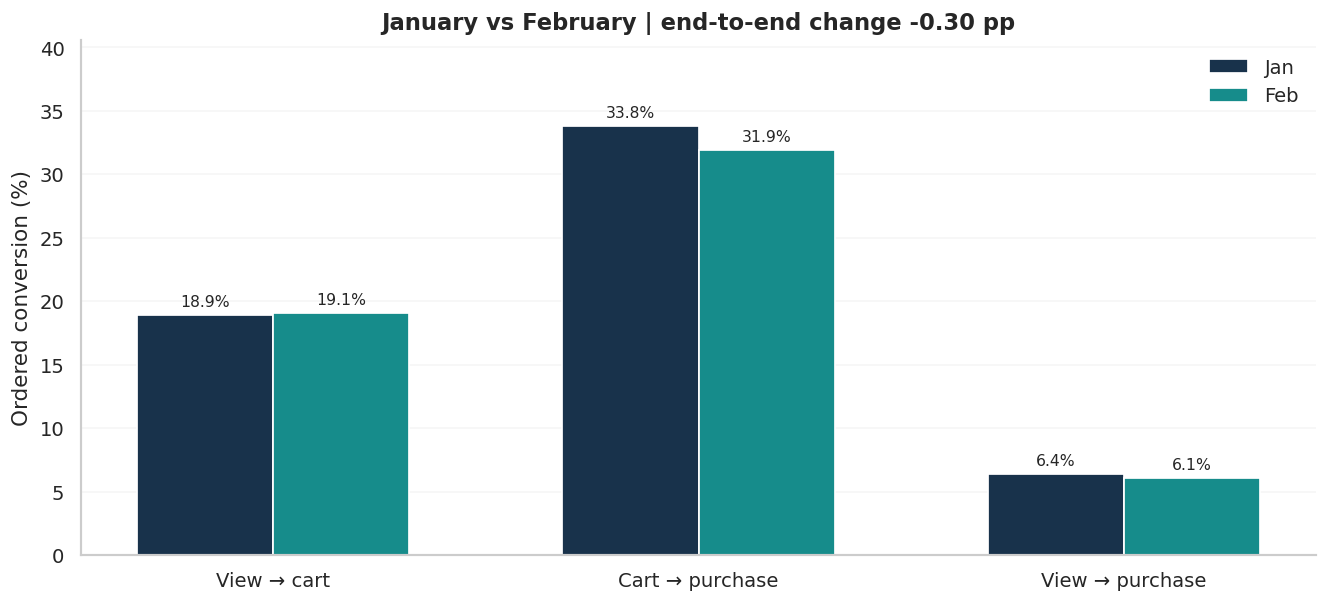

In [7]:
monthly = pd.DataFrame([{"month": m, "view users": s["view"], "cart users": s["cart"], "purchase users": s["purchase"],
                          "view → cart %": pct(s["cart"], s["view"]), "cart → purchase %": pct(s["purchase"], s["cart"]),
                          "view → purchase %": pct(s["purchase"], s["view"])} for m, s in ordered.items()]).set_index("month")
delta_pp = monthly.loc["Feb", "view → purchase %"] - monthly.loc["Jan", "view → purchase %"]
display(monthly.round(2))
print(f"Overall observed conversion: {delta_pp:+.2f} percentage points (Feb − Jan)")
chart = monthly[["view → cart %", "cart → purchase %", "view → purchase %"]].T
fig, ax = plt.subplots(figsize=(10.8, 5))
x = np.arange(len(chart)); width = .32
for shift, month, color in [(-width/2,"Jan",NAVY),(width/2,"Feb",TEAL)]:
    bars = ax.bar(x+shift, chart[month], width, label=month, color=color)
    for bar in bars:
        ax.annotate(f"{bar.get_height():.1f}%", (bar.get_x()+bar.get_width()/2, bar.get_height()), textcoords="offset points", xytext=(0,5), ha="center", fontsize=9)
ax.set_xticks(x, ["View → cart", "Cart → purchase", "View → purchase"])
ax.set_ylim(0, max(chart.to_numpy().flatten())*1.2)
ax.set(ylabel="Ordered conversion (%)", title=f"January vs February | end-to-end change {delta_pp:+.2f} pp")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
fig.tight_layout()
save_chart(fig, "monthly_conversion.png")

## Brands: purchasing scale versus efficiency

The top ten are selected by **purchase-event count**. Brand-level conversion is separately defined as *users who both viewed and purchased the same brand ÷ users who viewed the brand*. These numbers are neither order counts nor proof that users bought exactly the items they browsed.

Five largest labelled brands account for 25.3% of all recorded purchase events (including unlabelled purchases).


,brand,purchase events,view users,purchase users,view → purchase %
0,runail,45274,86823,15562,12.87
1,irisk,31210,70510,13332,12.51
2,grattol,21320,48870,7905,11.64
3,masura,19929,35640,5401,10.97
4,ingarden,10276,23716,4972,13.39
5,estel,8616,40234,3994,7.28
6,bpw.style,8437,13376,3070,14.60
7,uno,6871,22313,4128,9.99
8,italwax,6740,19923,2927,9.18
9,kapous,6370,42289,3018,4.86


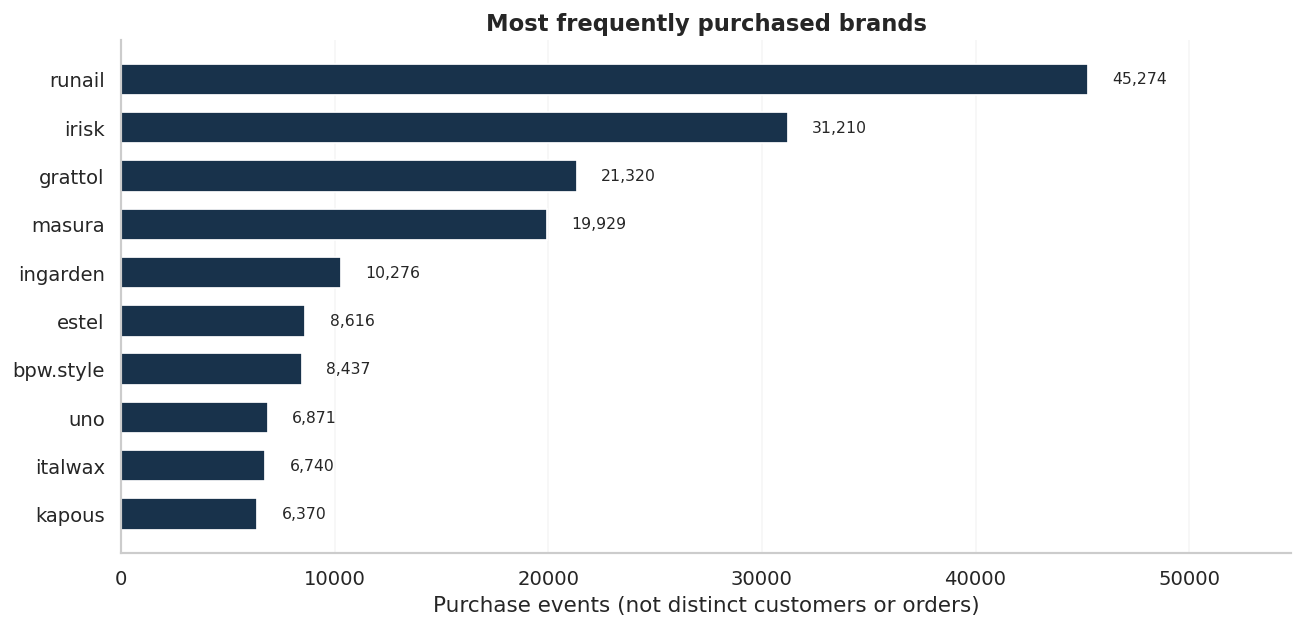

In [8]:
brand_rows = pd.concat(brand_fragments, ignore_index=True)
top_brands = [str(k) for k, _ in brand_purchase_counts.most_common(10)]
brand_rows = brand_rows.loc[brand_rows.brand.isin(top_brands)].drop_duplicates(["user_id", "brand", "event_type"])
brand_stats = []
for brand in top_brands:
    sub = brand_rows.loc[brand_rows.brand.eq(brand)]
    viewers = set(sub.loc[sub.event_type.eq("view"), "user_id"].astype("int64"))
    buyers = set(sub.loc[sub.event_type.eq("purchase"), "user_id"].astype("int64"))
    brand_stats.append({"brand": brand, "purchase events": brand_purchase_counts[brand], "view users": len(viewers),
                        "purchase users": len(buyers), "view → purchase %": pct(len(viewers & buyers), len(viewers))})
brand_stats = pd.DataFrame(brand_stats)
top_five_share = pct(sum(brand_purchase_counts[b] for b in top_brands[:5]), sum(event_counts[m,"purchase"] for m in FILES))
print(f"Five largest labelled brands account for {top_five_share:.1f}% of all recorded purchase events (including unlabelled purchases).")
display(brand_stats.round(2))
fig, ax = plt.subplots(figsize=(10.6, 5.2))
plot = brand_stats.sort_values("purchase events")
bars = ax.barh(plot.brand, plot["purchase events"], color=NAVY, height=.65)
ax.set_xlim(0, float(plot["purchase events"].max())*1.21)
for bar, val in zip(bars, plot["purchase events"]):
    ax.text(bar.get_width()+plot["purchase events"].max()*.025, bar.get_y()+bar.get_height()/2, f"{val:,}", va="center", fontsize=9)
ax.set(xlabel="Purchase events (not distinct customers or orders)", ylabel="", title="Most frequently purchased brands")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_chart(fig, "brand_purchase_ranking.png")

## Product rescue queue: a diagnostic, not an accusation

Products above the **90th percentile of view events** with a purchase/view event ratio in the bottom quartile of other high-exposure products are candidates for review. This ratio is **event-based**, not a user conversion probability. Repeated views and incomplete observation periods can distort it. Validate stock, content and price before recommending changes.

Review rule: views ≥ 164; purchase/view event ratio ≤ 4.85% (lower quartile of high-exposure products).


,product_id,view,cart,purchase,purchase / view events %
10474,5808664,17194,137,23,0.13
26659,5917178,13930,1124,344,2.47
44916,5924482,7842,748,214,2.73
21097,5877456,7800,259,21,0.27
17576,5856186,7761,517,79,1.02
7456,5769877,7608,398,66,0.87
16542,5850281,7482,525,80,1.07
21095,5877454,7230,566,82,1.13
2342,5649236,7046,1057,240,3.41
23599,5896420,6914,307,26,0.38


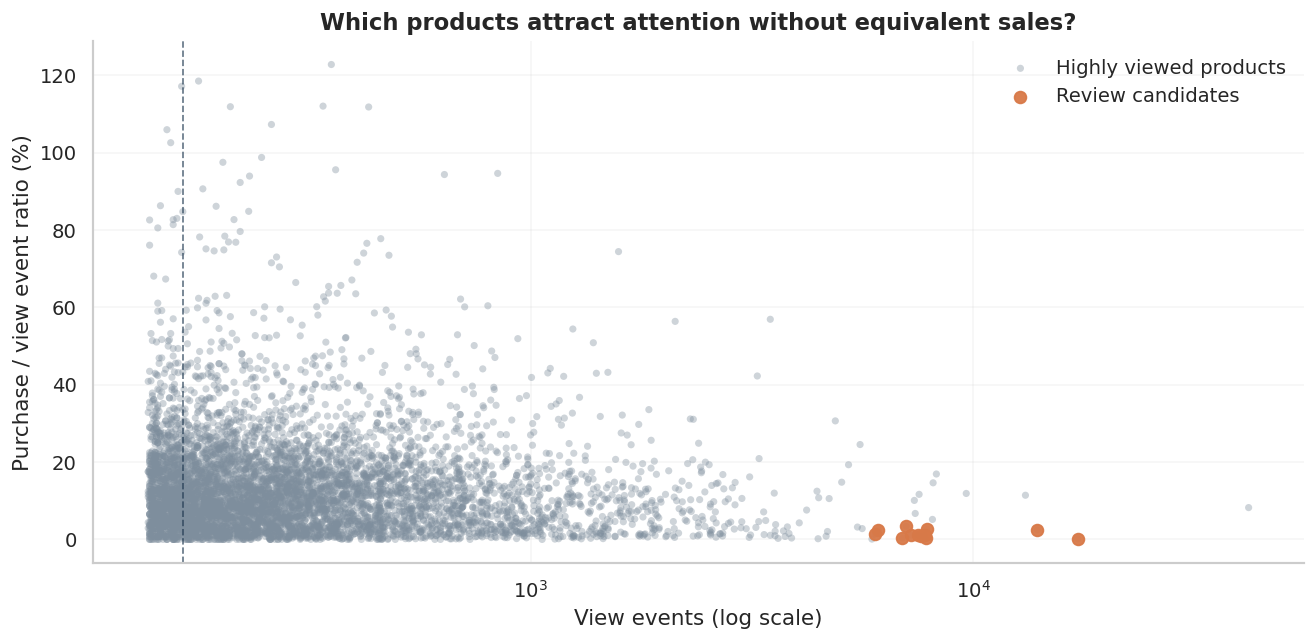

In [9]:
products = {}
for (product_id, event), count in product_counts.items():
    products.setdefault(product_id, {"view": 0, "cart": 0, "purchase": 0})[event] = count
product_stats = pd.DataFrame.from_dict(products, orient="index").rename_axis("product_id").reset_index()
product_stats = product_stats.loc[product_stats["view"].gt(0)].copy()
product_stats["purchase / view events %"] = 100*product_stats.purchase/product_stats["view"]
q90 = product_stats["view"].quantile(.90)
exposed = product_stats.loc[product_stats["view"].ge(q90)].copy()
low_cutoff = exposed["purchase / view events %"].quantile(.25)
friction = exposed.loc[exposed["purchase / view events %"].le(low_cutoff)].sort_values(["view","purchase"], ascending=[False,True]).head(12)
print(f"Review rule: views ≥ {q90:,.0f}; purchase/view event ratio ≤ {low_cutoff:.2f}% (lower quartile of high-exposure products).")
display(friction[["product_id", "view", "cart", "purchase", "purchase / view events %"]].round(2))
fig, ax = plt.subplots(figsize=(10.7, 5.3))
eligible_for_plot = product_stats.loc[product_stats["view"].ge(q90/2)]
plot = eligible_for_plot.nlargest(min(len(eligible_for_plot), 6000), "view")
ax.scatter(plot["view"], plot["purchase / view events %"], s=17, alpha=.38, color=GREY, edgecolors="none", label="Highly viewed products")
ax.scatter(friction["view"], friction["purchase / view events %"], s=46, alpha=.95, color=ORANGE, label="Review candidates")
ax.axvline(q90, linestyle="--", color=NAVY, lw=1, alpha=.65)
ax.set_xscale("log")
ax.set(xlabel="View events (log scale)", ylabel="Purchase / view event ratio (%)", title="Which products attract attention without equivalent sales?")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
save_chart(fig, "product_friction.png")

## Price anomalies and elapsed buying time

An IQR fence highlights **purchase-event price extremes**, not fraudulent transactions. Time-to-purchase is measured only for an ordered user-month path, from the first eligible view to the first purchase following the eligible cart. A purchase need not match the original viewed product. Both distributions have long tails, so medians and quantiles are more useful than a single unqualified average.

Price median $3.02; mean $5.00; IQR upper fence $11.52
IQR flagged 34,947 purchase events (6.9%); maximum $327.78
First view → purchase: median 3.35 hours; mean 77.65 hours; p90 286.42 hours | 48,528 journeys


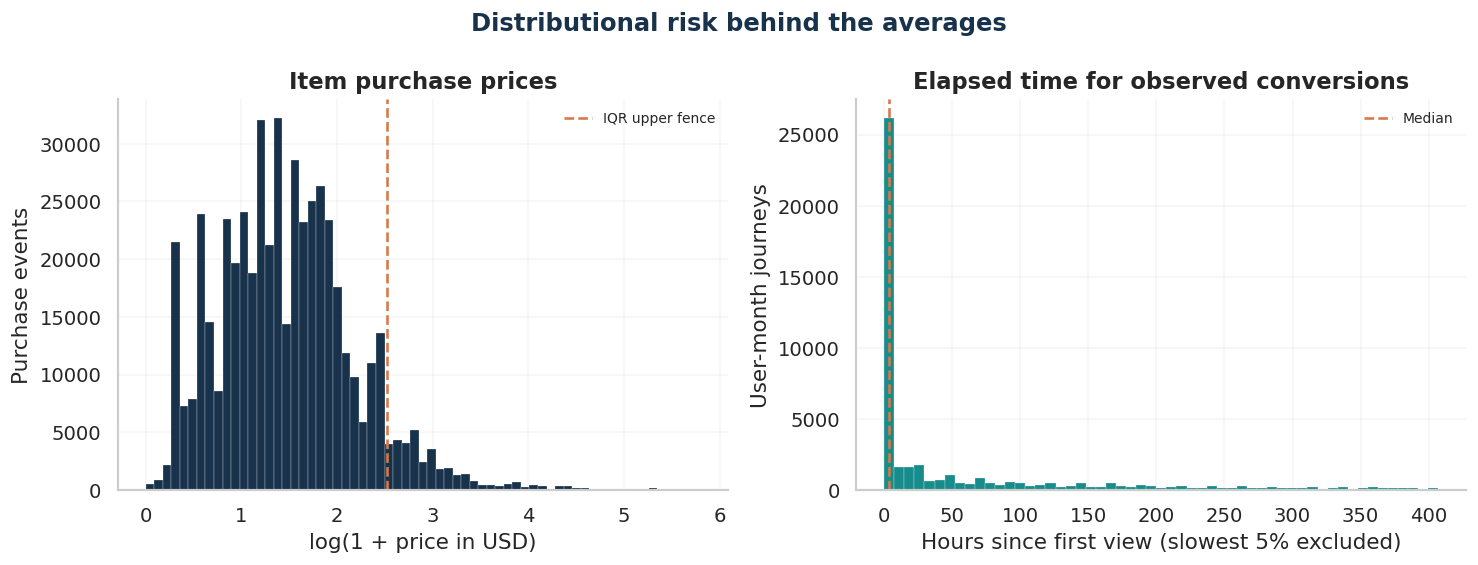

In [10]:
purchase_prices = pd.Series(np.concatenate(purchase_price_fragments), dtype="float64")
q1,q3 = purchase_prices.quantile([.25,.75]); iqr=q3-q1
low_fence, high_fence = q1-1.5*iqr, q3+1.5*iqr
outlier_mask = (purchase_prices.lt(low_fence) | purchase_prices.gt(high_fence))
print(f"Price median ${purchase_prices.median():,.2f}; mean ${purchase_prices.mean():,.2f}; IQR upper fence ${high_fence:,.2f}")
print(f"IQR flagged {outlier_mask.sum():,} purchase events ({outlier_mask.mean():.1%}); maximum ${purchase_prices.max():,.2f}")
print(f"First view → purchase: median {latency.median():.2f} hours; mean {latency.mean():.2f} hours; p90 {latency.quantile(.90):.2f} hours | {len(latency):,} journeys")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].hist(np.log1p(purchase_prices.clip(lower=0)), bins=65, color=NAVY, edgecolor="white", lw=.15)
axes[0].axvline(np.log1p(max(high_fence,0)), linestyle="--", color=ORANGE, label="IQR upper fence")
axes[0].set(title="Item purchase prices", xlabel="log(1 + price in USD)", ylabel="Purchase events")
axes[0].legend(frameon=False, fontsize=8)
latency_plot = latency.loc[latency.le(latency.quantile(.95))]
axes[1].hist(latency_plot, bins=55, color=TEAL, edgecolor="white", lw=.15)
axes[1].axvline(latency.median(), linestyle="--", color=ORANGE, label="Median")
axes[1].set(title="Elapsed time for observed conversions", xlabel="Hours since first view (slowest 5% excluded)", ylabel="User-month journeys")
axes[1].legend(frameon=False, fontsize=8)
fig.suptitle("Distributional risk behind the averages", fontsize=14, fontweight="bold", color=NAVY)
fig.tight_layout()
save_chart(fig, "price_and_purchase_latency.png")

## A useful extra signal: cart removals

The archive includes `remove_from_cart`, which is outside the assignment's required three-stage funnel. Comparing its volume to `cart` events can flag potential friction. **This is not a cart-abandonment rate**: a person may remove one product and still purchase another, and an event ratio is not the probability of a user abandoning checkout.

In [11]:
removal = pd.DataFrame([{"month": m, "cart events": event_counts[m,"cart"], "remove events": event_counts[m,"remove_from_cart"],
                         "remove/cart event ratio %": pct(event_counts[m,"remove_from_cart"], event_counts[m,"cart"])} for m in FILES]).set_index("month")
display(removal.round(2))

,cart events,remove events,remove/cart event ratio %
month,,,
Jan,1148323,815024,70.98
Feb,1148694,812409,70.72


## Findings that can guide a growth decision

Each observation below is calculated from the source data. The proposals remain hypotheses until supported by session-level funnel evidence, price/stock diagnostics or a controlled experiment.

In [12]:
category_leader = category_stats.loc[category_stats["view → purchase %"].idxmax()]
print("GROWTH REVIEW | verified descriptive signals")
print(f"• Discovery: {funnel["view"]-funnel.cart:,} observed viewer-journeys did not reach a qualifying cart ({100-rates['view → cart']:.1f}% of view-stage journeys).")
print(f"• Checkout: {funnel.cart-funnel.purchase:,} qualifying carts did not reach an observed purchase ({100-rates['cart → purchase']:.1f}% of cart-stage journeys).")
print(f"• Timing: February changed end-to-end conversion by {delta_pp:+.2f} pp; traffic and product mix could explain some or all of this difference.")
print(f"• Category: {category_leader['category']} leads the labelled top-eight view-to-purchase overlap ({category_leader['view → purchase %']:.1f}%), subject to category data coverage.")
print(f"• Focus: the top five labelled brands contribute {top_five_share:.1f}% of all purchase events, while {len(friction)} high-exposure products enter the rescue shortlist.")
print(f"• Speed: median time from first view to eligible purchase is {latency.median():.2f} hours among ordered converters, not among all visitors.")

GROWTH REVIEW | verified descriptive signals
• Discovery: 629,337 observed viewer-journeys did not reach a qualifying cart (81.0% of view-stage journeys).
• Checkout: 99,156 qualifying carts did not reach an observed purchase (67.1% of cart-stage journeys).
• Timing: February changed end-to-end conversion by -0.30 pp; traffic and product mix could explain some or all of this difference.
• Category: apparel.glove leads the labelled top-eight view-to-purchase overlap (18.4%), subject to category data coverage.
• Focus: the top five labelled brands contribute 25.3% of all purchase events, while 12 high-exposure products enter the rescue shortlist.
• Speed: median time from first view to eligible purchase is 3.35 hours among ordered converters, not among all visitors.


## Reproducibility and measurement checks

The assertions verify funnel monotonicity, rate bounds, counts at each aggregation grain, exact chart delivery, and the source scope. The data quality table and explicit measurement definitions provide an additional methodological audit. The five growth observations are **descriptive**, never causal.

In [13]:
assert sum(audit[m,"rows"] for m in FILES) == sum(event_counts[m,e] for m in FILES for e in event_mix.index)
assert all((monthly_users["view"] >= monthly_users["cart"]) & (monthly_users["cart"] >= monthly_users["purchase"]))
assert all(0<= v <=100 for v in rates.values())
assert np.isclose(rates["view → purchase"], rates["view → cart"]*rates["cart → purchase"]/100)
assert monthly_users["view"].sum() == funnel["view"]
assert len(top_categories) <= 8 and len(top_brands) <= 10
expected_charts = ["funnel_user_journey.png", "transition_dropoff.png", "category_conversion.png", "monthly_conversion.png", "brand_purchase_ranking.png", "product_friction.png", "price_and_purchase_latency.png"]
assert all((VIZ/f).exists() and (VIZ/f).stat().st_size>8_000 for f in expected_charts)
print(f"Validation passed | {sum(audit[m,'rows'] for m in FILES):,} source events | {len(expected_charts)} chart files | {len(FILES)} months")
print("Notebook executed successfully. Saved charts:")
for filename in expected_charts:
    print("   visuals/" + filename)

Validation passed | 8,421,434 source events | 7 chart files | 2 months
Notebook executed successfully. Saved charts:
   visuals/funnel_user_journey.png
   visuals/transition_dropoff.png
   visuals/category_conversion.png
   visuals/monthly_conversion.png
   visuals/brand_purchase_ranking.png
   visuals/product_friction.png
   visuals/price_and_purchase_latency.png
